# Part 1: Dataset discovery & exploration
**Lab:** In God we trust, everyone else bring the data · **Analyst:** Ayhan Demir · **Notebook 1 of 5**

**Scenario:** the CMO wants to split a **$500K monthly budget** across the marketing channels and asks for a **statistically rigorous** recommendation. A false positive means moving money to a channel that isn't really better.

| Notebook | Part | Reads | Writes to `outputs/` |
|---|---|---|---|
| **01_data_exploration** | **1: find, load, clean, metrics** | **Kaggle (kagglehub)** | **marketing_data.csv, group_metrics_overview.png, group_distributions.png** |
| 02_pairwise_comparisons | 2: t-tests, Cohen's d, Fisher | marketing_data.csv | results_*.csv, metric_comparison_heatmap.png, rate_comparison.png |
| 03_multiple_comparisons | 3: Bonferroni vs BH | results_*.csv | results_*.csv (+ corrections), correction_comparison.png |
| 04_power_analysis | 4: power and sample size | marketing_data.csv, results_cpa_ttest.csv | power_*.csv, power_analysis_cpa.png |
| 05_business_recommendations | 5: CIs, budget split, memo | all of the above | executive_memo.md |

**Run the notebooks in order (01 → 05), each top to bottom.**


## Step 1: Find a dataset
The lab asks for a Kaggle or Hugging Face dataset with **3+ groups**, the **performance columns** (impressions, clicks, conversions, cost, revenue) and **repeated rows per group**, ideally one row per day, so t-tests and power have a spread to work with.

**✍️ Document your choice here:**
- **Dataset name:** Online Advertising Digital Marketing data (file: Online Advertising Performance Data)
- **Source + URL:** Kaggle, https://www.kaggle.com/datasets/naniruddhan/online-advertising-digital-marketing-data
- **Why I chose it:** real advertiser data ("Company X"), **daily** rows from 1 Apr to 30 Jun 2020 (**91 days**, which matches the lab's "90 days" power check), **5 named placements** to compare, and **all five metrics**. The other candidates were synthetic, had only 3 groups, or had one row per campaign or per customer.
- **What is one row?** In the raw file: one day × campaign × banner size × placement × engagement level. After cleaning I add these up to **one row = one day for one placement** (5 placements × 91 days).

**Two reading choices (documented so a reviewer can check them):**
- **Channel = placement**: the publisher site where the ads run, which is where the budget goes. Banner size is a creative choice, not a channel.
- **Cost and revenue from the CMO's side (Company X):** in this file `revenue` is *the price Company X pays the ad firm for the clicks*, so it becomes our **cost**; `post_click_sales_amount` (sales after the click) becomes our **revenue**. The file's own `cost` column is the ad firm's cost to the publisher, so it is dropped.

### Setup
- Loads the libraries used in this lab: pandas/numpy for tables, matplotlib/seaborn for charts, `scipy.stats` for the tests.
- `rng` is the fixed random "dice" (seed 42), so simulations and bootstraps give the same numbers every run.
- `OUT` is the `outputs/` folder where every chart, CSV and the memo are saved. `ALPHA = 0.05` is the significance line.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Step 2: Load, explore, clean
**What & why**
- Rename the columns to the **standard names** (`date, channel, impressions, clicks, conversions, cost, revenue`).

**2a. Load and explore**
- `kagglehub` downloads the dataset straight from Kaggle on the first run and reuses the local cache afterwards. No login is needed for a public dataset.
- The download also holds the dataset's own description file (`.txt`). It is printed so you can see the column definitions behind the cost/revenue choice.
- The file's own `cost` column is dropped **before** renaming, otherwise there would be two columns called `cost`.

In [ ]:
%pip install -q kagglehub
import kagglehub

# Download latest version (cached after the first run)
path = kagglehub.dataset_download("naniruddhan/online-advertising-digital-marketing-data")
print("Path to dataset files:", path)

# The dataset's own description file: column definitions
for txt in Path(path).glob("*.txt"):
    print(txt.read_text(errors="ignore"))

CSV_PATH = next(Path(path).glob("*.csv"))         # the one CSV in the download
COLUMN_MAP = {
    "placement": "channel",                       # publisher site = our channel
    "displays": "impressions",                    # ads shown
    "post_click_conversions": "conversions",      # conversions after a click
    "revenue": "cost",                            # what Company X pays the ad firm = the CMO's cost
    "post_click_sales_amount": "revenue",         # sales after the click = the CMO's revenue
}

raw = pd.read_csv(CSV_PATH).drop(columns=["cost"])   # drop the ad firm's own cost first (avoids two "cost" columns)
raw = raw.rename(columns=COLUMN_MAP)

# Explore: shape, column types, first rows
print("Shape:", raw.shape)
print(raw.dtypes)
raw.head()

Note: you may need to restart the kernel to use updated packages.


/opt/anaconda3/envs/bootcamp-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 220k/220k [00:00<00:00, 1.18MB/s]

Extracting files...


Path to dataset files: /Users/macbook-air/.cache/kagglehub/datasets/naniruddhan/online-advertising-digital-marketing-data/versions/1
Online Advertising Performance Data

The dataset provides insights into the online advertising performance of a company, referred to as "Company X", from April 1, 2020, to June 30, 2020. The currency used for transactions is the US dollar.

Metrics:

Day: Date of the advertising campaign.
Campaign: A segmentation variable set by Company X to target specific groups of users with advertisements.
User Engagement: Indicates the level of engagement of users targeted by the advertising campaign.
Banner: Represents the size of the ad served by an advertising platform, referred to as "Advert Firm A".
Placement: Denotes the publisher space where the ad is served by "Advert Firm A", such as websites or apps.
Displays: The number of ads served by "Advert Firm A" during the campaign period.
Cost: The price paid by "Advert Firm A" to serve the ads to the publisher. It

,month,day,campaign_number,user_engagement,banner,channel,impressions,clicks,cost,conversions,revenue,Unnamed: 12,Unnamed: 13
0,April,1,camp 1,High,160 x 600,abc,4,0,0.0000,0,0.0000,NaN,NaN
1,April,1,camp 1,High,160 x 600,def,20170,158,28.9717,23,1972.4602,NaN,NaN
2,April,1,camp 1,High,160 x 600,ghi,14701,158,28.9771,78,2497.2636,NaN,NaN
3,April,1,camp 1,High,160 x 600,mno,171259,1796,329.4518,617,24625.3234,NaN,NaN
4,April,1,camp 1,Low,160 x 600,def,552,1,0.1834,0,0.0000,NaN,NaN


**2b. Clean**
- **Housekeeping first:** drop the two empty export columns, exact duplicate rows, and rows with no placement. A row without a placement can't be given to a channel.
- **Fix types:** the file has a month name plus a day number (no year), so the date is built with year 2020. The numeric columns are forced to numbers.
- **Remove impossible rows,** exactly as the template says: negative values, clicks > impressions, conversions > clicks.
- **Sum to one row per day per channel.** Campaigns, banners and engagement levels are added together, because we compare **placements**. The number of days per channel becomes the **N** for the t-tests.

In [3]:
df = raw.copy()
num_cols = ["impressions", "clicks", "conversions", "cost", "revenue"]   # we have all five

# 0. Housekeeping: empty export columns, exact duplicates, rows without a placement
df = df.dropna(axis=1, how="all")
print("Duplicate rows removed:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows without a placement removed:", df["channel"].isna().sum())
df = df.dropna(subset=["channel"])

# 1. Real date (month name + day, year 2020) and numeric columns
df["date"] = pd.to_datetime("2020 " + df["month"] + " " + df["day"].astype(str), format="%Y %B %d")
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2. Missing values, then remove impossible rows
print("\nMissing values per column:\n", df[num_cols].isna().sum().to_string())
negative = (df[num_cols] < 0).any(axis=1)
too_many_clicks = df.clicks > df.impressions
too_many_conv = df.conversions > df.clicks
print(f"\nImpossible rows: negative={negative.sum()}, clicks>impressions={too_many_clicks.sum()}, conversions>clicks={too_many_conv.sum()}")
df = df[~(negative | too_many_clicks | too_many_conv)]
print("Rows left:", len(df))

# Sum to one row per day per channel (campaigns, banners, engagement levels added together)
df = df.groupby(["date", "channel"], as_index=False)[num_cols].sum()

# 3. Groups, rows per group (= N for the t-tests), date range
print("\nNumber of groups:", df["channel"].nunique())
print("Rows (days) per group:\n", df["channel"].value_counts().sort_index().to_string())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

# 4. Save the cleaned data
df.to_csv(OUT / "marketing_data.csv", index=False)

Duplicate rows removed: 5
Rows without a placement removed: 413

Missing values per column:
 impressions    0
clicks         0
conversions    0
cost           0
revenue        0

Impossible rows: negative=0, clicks>impressions=2, conversions>clicks=326
Rows left: 14662

Number of groups: 5
Rows (days) per group:
 channel
abc    91
def    91
ghi    91
jkl    91
mno    91
Date range: 2020-04-01 to 2020-06-30


**✍️ Transformations I made:**
1. **Loaded** with `kagglehub` and renamed to the standard names: placement → `channel`, displays → `impressions`, post_click_conversions → `conversions`, revenue → `cost`, post_click_sales_amount → `revenue`. Dropped the file's own `cost` column (the ad firm's cost to the publisher).
2. **Housekeeping:** dropped 2 empty export columns, **5** exact duplicate rows and **413** rows with no placement.
3. **Types:** built `date` from month + day (year 2020). All metric columns were already numeric, with no missing values.
4. **Impossible rows removed:** 0 negative, **2** with clicks > impressions, **326** with conversions > clicks. That leaves 14,662 rows.
5. **Aggregated** to one row per day per placement: **455 rows = 5 channels × 91 days** (1 Apr to 30 Jun 2020), saved as `outputs/marketing_data.csv`.


### Step 3: Key marketing metrics
| Metric | Formula |
|---|---|
| CTR | clicks / impressions |
| Conversion rate | conversions / clicks |
| CPA | cost / conversions (lower is better) |
| ROAS | revenue / cost (higher is better) |
| Profit · margin | revenue − cost · profit / revenue |

**3a. Totals per channel, then the metrics**
- These are **channel totals** for the whole period, used for the summary table and the overview chart.
- `.where(agg.cost > 0)` follows the hint: a channel with zero cost gets **no CPA**, instead of a fake "$0 = best".

In [4]:
agg = df.groupby("channel")[num_cols].sum()
agg["CTR"] = agg.clicks / agg.impressions
agg["conv_rate"] = agg.conversions / agg.clicks
agg["CPA"] = (agg.cost / agg.conversions).where(agg.cost > 0)   # zero-cost channel -> no CPA
agg["ROAS"] = agg.revenue / agg.cost
agg["profit"] = agg.revenue - agg.cost
agg["profit_margin"] = agg.profit / agg.revenue
agg = agg.replace([np.inf, -np.inf], np.nan)
agg.round(3)

,impressions,clicks,conversions,cost,revenue,CTR,conv_rate,CPA,ROAS,profit,profit_margin
channel,,,,,,,,,,,
abc,221584,1477,618,131.660,3.533177e+04,0.007,0.418,0.213,268.356,3.520011e+04,0.996
def,27444482,173646,26716,15579.244,1.434841e+06,0.006,0.154,0.583,92.100,1.419262e+06,0.989
ghi,59195165,1242602,331992,151063.181,1.623298e+07,0.021,0.267,0.455,107.458,1.608191e+07,0.991
jkl,7452402,73754,19200,8115.213,1.005797e+06,0.010,0.260,0.423,123.940,9.976820e+05,0.992
mno,135523588,960577,225991,96912.287,1.181927e+07,0.007,0.235,0.429,121.958,1.172236e+07,0.992


**3b. Overview chart (2 × 3 horizontal bars)**
- One small chart per metric, sorted, so the best and worst channel are easy to spot.
- The profit chart gets a black line at 0, so loss-making channels would stand out.

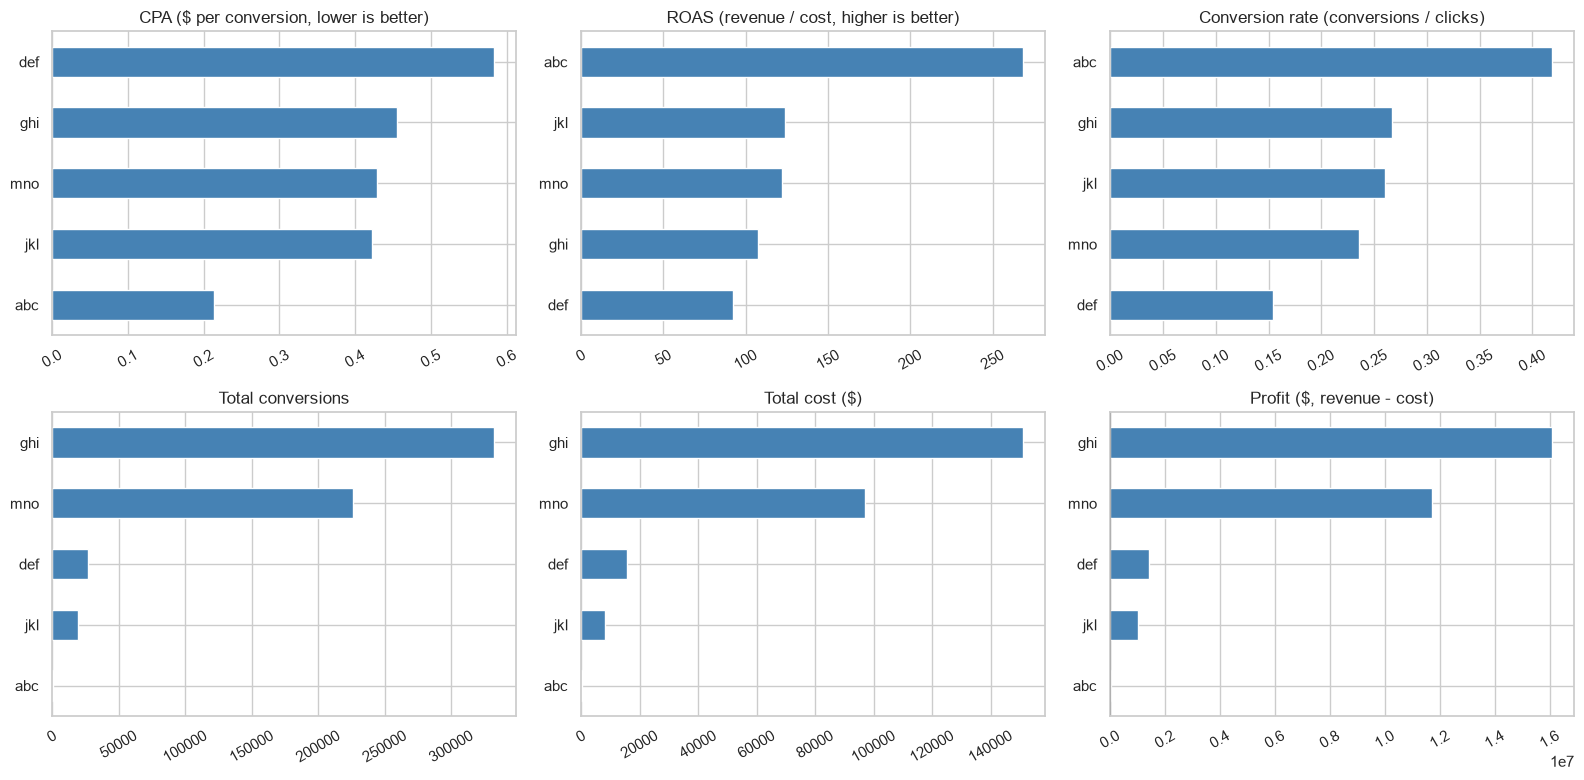

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
charts = [("CPA", "CPA ($ per conversion, lower is better)"),
          ("ROAS", "ROAS (revenue / cost, higher is better)"),
          ("conv_rate", "Conversion rate (conversions / clicks)"),
          ("conversions", "Total conversions"),
          ("cost", "Total cost ($)"),
          ("profit", "Profit ($, revenue - cost)")]
for ax, (col, title) in zip(axes.flat, charts):
    agg[col].sort_values().plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(title)
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelrotation=30)     # keep long numbers readable
# Profit chart: add a vertical line at 0 (ax.axvline(0, color="black"))
axes.flat[5].axvline(0, color="black")
plt.tight_layout()
plt.savefig(OUT / "group_metrics_overview.png", dpi=120)
plt.show()

**3c. Daily metrics, distributions and spread**
- **Why daily:** a channel total gives one number per channel, so it has no spread. Daily CPA gives about 91 values per channel, and their **spread** is what the t-test in notebook 02 compares the gap with.
- `paid` keeps only days with spend (cost > 0). Days with zero conversions get no CPA (division by zero becomes NaN).
- **CV = std / mean** compares spread across channels with different CPA levels.

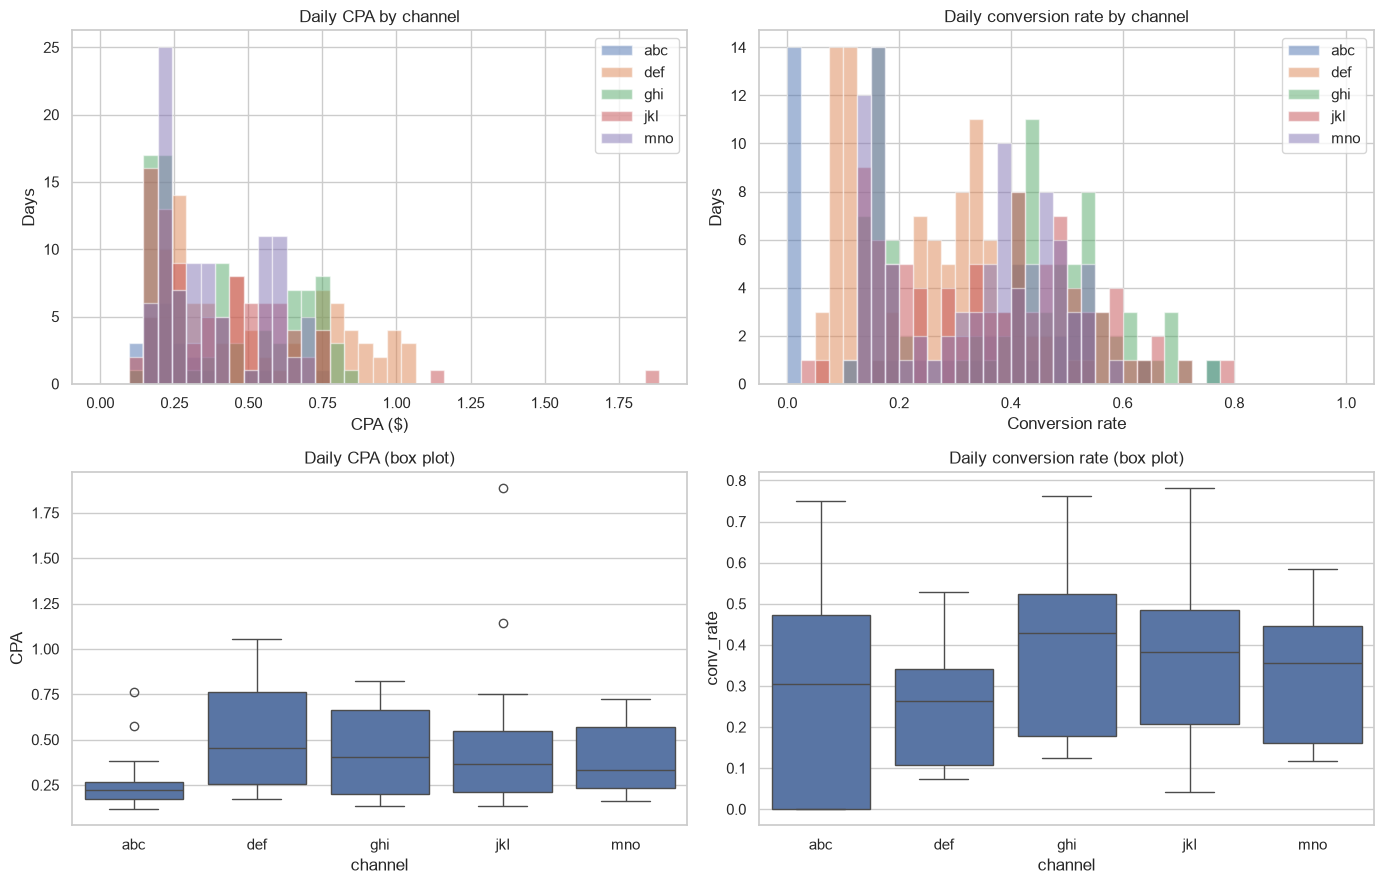

,count,mean,std,CV
channel,,,,
abc,22,0.257,0.151,0.588
def,91,0.510,0.273,0.536
ghi,91,0.416,0.227,0.546
jkl,91,0.405,0.254,0.626
mno,91,0.381,0.170,0.447


In [6]:
df["CPA"] = df.cost / df.conversions
df["conv_rate"] = df.conversions / df.clicks
df = df.replace([np.inf, -np.inf], np.nan)
paid = df[df.cost > 0]

# Histograms (overlaid, alpha=0.5) and box plots of daily CPA and conversion rate
channels = sorted(df.channel.unique())
cpa_bins = np.linspace(0, paid.CPA.max(), 40)       # same bins for every channel, so the bars are comparable
cvr_bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ch in channels:
    axes[0, 0].hist(paid.loc[paid.channel == ch, "CPA"].dropna(), bins=cpa_bins, alpha=0.5, label=ch)
    axes[0, 1].hist(df.loc[df.channel == ch, "conv_rate"].dropna(), bins=cvr_bins, alpha=0.5, label=ch)
axes[0, 0].set(title="Daily CPA by channel", xlabel="CPA ($)", ylabel="Days")
axes[0, 1].set(title="Daily conversion rate by channel", xlabel="Conversion rate", ylabel="Days")
axes[0, 0].legend()
axes[0, 1].legend()
sns.boxplot(data=paid, x="channel", y="CPA", order=channels, ax=axes[1, 0])
sns.boxplot(data=df, x="channel", y="conv_rate", order=channels, ax=axes[1, 1])
axes[1, 0].set_title("Daily CPA (box plot)")
axes[1, 1].set_title("Daily conversion rate (box plot)")
plt.tight_layout()
plt.savefig(OUT / "group_distributions.png", dpi=120)
plt.show()

# Spread per channel: mean, std and CV = std / mean of daily CPA
variability = paid.groupby("channel")["CPA"].agg(["count", "mean", "std"])
variability["CV"] = variability["std"] / variability["mean"]
variability.round(3)

**✍️ Key insights**
- **Best on each metric:** `abc` has the lowest CPA ($0.21), the highest ROAS (268x) and the highest conversion rate (41.8%). `ghi` has by far the highest CTR (2.1%) and the most conversions (332K). `def` is worst on CPA ($0.58), ROAS (92x) and conversion rate (15.4%).
- **Scale is very uneven:** `abc` spent only **$132** in 91 days (0.05% of all spend), against $151K for `ghi` and $97K for `mno`. Its "best" numbers come from 1,477 clicks.
- **Most variable:** daily CPA moves a lot for every channel (CV 0.45 to 0.63). `jkl` is the most variable (CV 0.63, driven by two extreme days), and `mno` is the steadiest (0.45). `def` has the widest box: a high typical CPA *and* a big spread.
- **Outliers:** `jkl` has two extreme CPA days ($1.14 and $1.88), and `abc` has two ($0.57 and $0.76). `abc` also has 14 days with clicks but zero conversions (its conversion-rate box starts at 0).
- **Channels that look close:** `ghi`, `jkl` and `mno` (average daily CPA $0.38 to $0.42; conversion rates 23.5% to 26.7%). These are the pairs to watch in the t-tests.
- **A ROAS of 92x to 268x** is far above normal e-commerce levels, because the revenue column credits all post-click sales to the ad. It is useful for ranking channels, not as a profit forecast.